# 05 · Phase 5: Unseen batch (RQ5) and interpretation (SHAP)

**Question.** How do the frozen models of Phases 2–4 transfer to a batch none of them has seen: 2018-02-20 (`u1`,
39 labelled cells: 30 standard, 9 `-newstructure`)? It is not part of the paper, so there are no published numbers.

**Protocol.** No refitting or re-tuning. Five hypotheses with decision rules were written into `src/p5_unseen.py`
before any u1 life was used; u1 was evaluated once. A GP on F3 + F4 was added afterwards and is labelled exploratory.

**Prerequisites** (repo root):
```
python3 -m src.p5_unseen && python3 -m src.p5_shap && python3 -m src.p5_gp_full
```

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
from config import RESULTS_DIR
from src.features import load_features, FEATURE_SETS
import src.p5_unseen as p5
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
U = json.load(open(RESULTS_DIR / "p5_unseen.json")); S = json.load(open(RESULTS_DIR / "p5_shap.json"))
G = json.load(open(RESULTS_DIR / "p5_gp_full.json"))
df = load_features(); tr = df[df.split == "train"]; u = df[df.split == "unseen"]
ns = u.policy.str.contains("newstructure")
FIG = ROOT / "report" / "figures"
print(U["n"])

{'all': 39, 'standard': 30, 'newstructure': 9}


## 1 · What is different about u1 (inputs only)
Median z-score of each feature against the training cells, per group; share of cells beyond 3 SD.

In [2]:
cols = sorted(set(FEATURE_SETS["full"]) | set(FEATURE_SETS["discharge"]) | set(FEATURE_SETS["physics"]))
z = (u[cols] - tr[cols].mean()) / tr[cols].std()
pd.DataFrame({"standard": z[~ns].median(), "newstructure": z[ns].median(), "share |z|>3": (z.abs() > 3).mean()}).round(2)

,standard,newstructure,share |z|>3
chargetime_avg_2_6,-0.44,-0.61,0.00
dq_log_kurt,0.03,2.58,0.10
dq_log_min,0.51,-1.74,0.00
dq_log_skew,0.22,0.74,0.00
dq_log_var,0.54,-1.54,0.00
ir_100_minus_2,-0.39,0.39,0.00
ir_min_2_100,-0.21,-2.63,0.00
margin_rate,-0.37,1.69,0.00
overhang_after10,2.61,-0.60,0.38
qd_2,2.59,1.95,0.26


## 2 · The pre-registered hypotheses (as written in the code before the run)

In [3]:
print(p5.__doc__.split("PRE-REGISTERED HYPOTHESES")[1].split("Usage:")[0])

 (fixed 2026-11-11, before any u1 life was used; decision
rules are evaluated mechanically in `verdicts`):
  H1  Models separate standard from newstructure cells but rank cells poorly
      within each group.  Supported if, for at least 3 of the 4 main models,
      Spearman rho(pred, life) >= 0.7 over all u1 cells and < 0.5 within each group.
  H2  Overhang: u1 standard cells have a late, large overhang rise (z = +2.6), so
      their ΔQ understates degradation. Supported if EN-F2's mean signed % error on
      standard cells is > 0 (over-prediction), its log residual correlates
      positively with overhang_after10 within the standard cells (Spearman > 0),
      and EN-F4 and GP-F4 have a smaller |mean signed % error| than EN-F2 there.
  H3  Procedure: u1 newstructure cells (5-s rests, like b3) are mispredicted in the
      same direction as the secondary set. Supported if the sign of the mean signed
      % error on u1 newstructure equals that on the secondary set for >= 3 of the 4

## 3 · Results: RMSE / % error / bias (signed % error) per group

,all,standard,newstructure
en_variance,119 / 15.2% / +11%,77 / 14.3% / +10%,204 / 18.5% / +17%
en_discharge,260 / 27.1% / +27%,104 / 20.4% / +20%,506 / 49.5% / +50%
en_full,138 / 12.8% / +12%,51 / 9.2% / +9%,271 / 24.6% / +23%
en_physics,178 / 20.4% / -2%,97 / 17.6% / -11%,325 / 30.0% / +30%
en_full_physics,124 / 9.2% / +6%,28 / 5.0% / +0%,254 / 23.0% / +23%
gp_discharge,237 / 26.0% / +26%,102 / 20.5% / +20%,458 / 44.4% / +44%
svr_discharge,242 / 33.2% / +33%,144 / 30.3% / +30%,430 / 42.7% / +43%
gam_discharge,346 / 38.8% / +38%,183 / 31.8% / +31%,639 / 61.9% / +62%
gp_physics,158 / 13.9% / +9%,49 / 9.1% / +2%,316 / 30.1% / +30%
svr_physics,587 / 69.0% / +68%,624 / 76.2% / +75%,440 / 45.0% / +45%


GP 95% coverage: {'gp_discharge': {'all': 0.79, 'standard': 0.87, 'newstructure': 0.56, 'median_interval_factor': 1.38}, 'gp_physics': {'all': 0.87, 'standard': 0.97, 'newstructure': 0.56, 'median_interval_factor': 1.26}}
bootstrap all: en_physics-en_discharge -80 [-121,-37]  gp_physics-en_physics -21 [-38,-7]  en_full-en_discharge -121 [-189,-44]  en_discharge-policy_mean +20 [-78,+116]
bootstrap standard: en_physics-en_discharge -7 [-36,+25]  gp_physics-en_physics -48 [-66,-30]  en_full-en_discharge -53 [-69,-35]  en_discharge-policy_mean -64 [-99,-30]
bootstrap newstructure: en_physics-en_discharge -182 [-252,-119]  gp_physics-en_physics -8 [-31,+15]  en_full-en_discharge -234 [-369,-75]  en_discharge-policy_mean +120 [-100,+324]


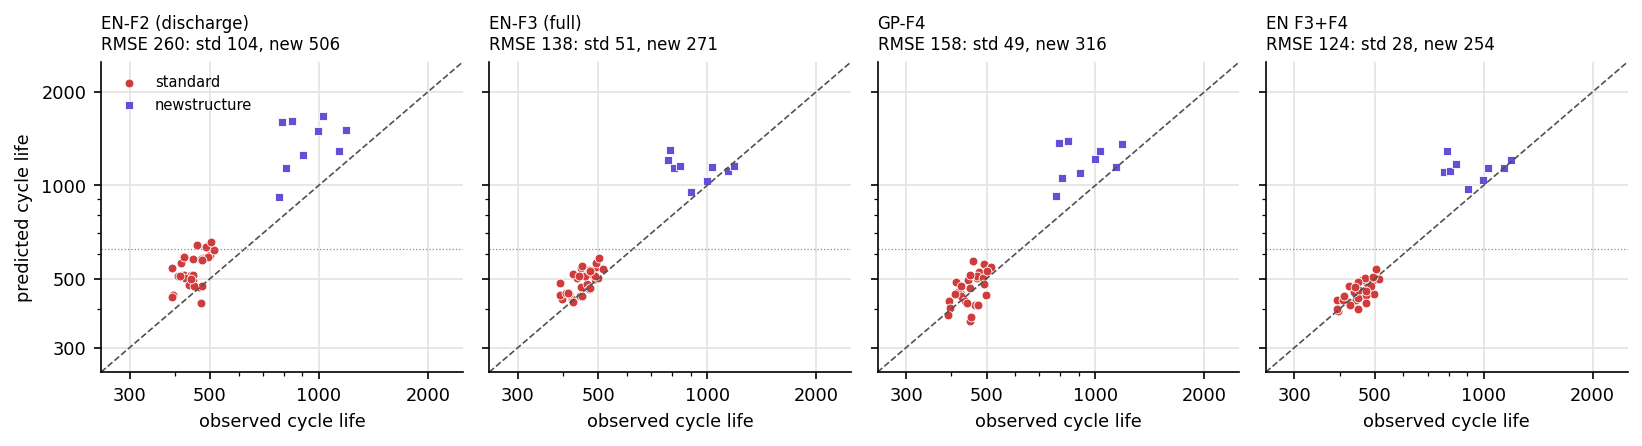

In [4]:
rows = {}
for k, s in U["scores"].items():
    rows[k] = {g: f"{s[g]['rmse']:.0f} / {s[g]['mape']:.1f}% / {s[g]['signed_pct']:+.0f}%" for g in ("all", "standard", "newstructure")}
display(pd.DataFrame(rows).T)
print("GP 95% coverage:", {k: {g: round(x, 2) for g, x in v.items()} for k, v in U["gp_coverage"].items()})
for g, b in U["bootstrap"].items():
    print(f"bootstrap {g}: " + "  ".join(f"{p} {w['diff']:+.0f} [{w['ci'][0]:+.0f},{w['ci'][1]:+.0f}]" for p, w in b.items()))
display(Image(str(FIG / "fig_p5_parity.png"), width=980))

## 4 · Verdicts

In [5]:
print(json.dumps(U["hypotheses"], indent=1, default=float))
print("VERDICTS:", U["verdicts"])

{
 "H1": {
  "EN-F2": {
   "rho_all": 0.7998785343135724,
   "rho_standard": 0.5769915585660366,
   "rho_newstructure": 0.3666666666666667
  },
  "EN-F3": {
   "rho_all": 0.8176941027822117,
   "rho_standard": 0.6388518182194721,
   "rho_newstructure": -0.48333333333333334
  },
  "EN-F4": {
   "rho_all": 0.6152444610931274,
   "rho_standard": 0.1693368978282892,
   "rho_newstructure": 0.43333333333333335
  },
  "GP-F4": {
   "rho_all": 0.7523028685166374,
   "rho_standard": 0.4750778933815998,
   "rho_newstructure": 0.26666666666666666
  }
 },
 "H2": {
  "enf2_signed_pct_standard": 19.682951958174247,
  "rho_resid_enf2_vs_overhang_standard": -0.4318131256952169,
  "abs_signed_pct_standard": {
   "EN-F2": 19.682951958174247,
   "EN-F3": 8.680076364435916,
   "EN-F4": 11.303234195042421,
   "GP-F4": 2.3467986375780474
  }
 },
 "H3": {
  "EN-F2": {
   "u1_newstructure": 49.5223952673378,
   "secondary": 3.193188222453426
  },
  "EN-F3": {
   "u1_newstructure": 23.41482822969158,
   "secon

* **H1 no:** the paper's models rank the standard cells better than expected (ρ 0.58 / 0.64).
* **H2 no:** the group pattern fits (F2 over-predicts standard cells, F4 models less biased) but within the standard
  cells the residual *decreases* with the overhang rise (ρ = −0.43): the overhang explanation of Phase 3 is not confirmed.
* **H3 yes, weakly:** same sign as the secondary set, but +23 to +50% here vs ±3–5% there.
* **H4 yes:** the temperature integral lowers the standard cells by ≈19% (and helps).
* **H5 yes:** GP-F4 covers 97% of standard cells but 56% of `-newstructure` cells.

## 5 · SHAP interpretation
Exact SHAP values of predicted log10 life, training cells as background. ΔQ min and variance are nearly collinear;
read them together.


EN-F2: share of mean |SHAP| (%)


,train,primary,secondary,u1_standard,u1_newstructure
dq_log_min,35.0,37.0,39.0,23.0,35.0
dq_log_var,29.0,30.0,31.0,19.0,28.0
dq_log_skew,4.0,4.0,2.0,3.0,2.0
dq_log_kurt,7.0,9.0,6.0,6.0,10.0
qd_2,12.0,12.0,11.0,27.0,14.0
qd_max_minus_2,13.0,10.0,10.0,22.0,10.0



EN-F3: share of mean |SHAP| (%)


,train,primary,secondary,u1_standard,u1_newstructure
dq_log_min,19.0,20.0,21.0,11.0,23.0
dq_log_var,23.0,24.0,25.0,14.0,27.0
qd_2,12.0,11.0,11.0,26.0,16.0
chargetime_avg_2_6,16.0,18.0,7.0,6.0,6.0
temp_integral_2_100,18.0,17.0,19.0,37.0,17.0
ir_min_2_100,11.0,10.0,16.0,6.0,11.0
ir_100_minus_2,0.0,0.0,0.0,0.0,0.0



GP-F4: share of mean |SHAP| (%)


,train,primary,secondary,u1_standard,u1_newstructure
margin_rate,74.0,76.0,88.0,49.0,90.0
overhang_after10,26.0,24.0,12.0,51.0,10.0



EN-F3+F4: share of mean |SHAP| (%)


,train,primary,secondary,u1_standard,u1_newstructure
dq_log_min,12.0,13.0,15.0,7.0,15.0
dq_log_var,14.0,15.0,16.0,9.0,17.0
qd_2,8.0,7.0,8.0,18.0,11.0
chargetime_avg_2_6,14.0,15.0,6.0,5.0,5.0
temp_integral_2_100,18.0,17.0,20.0,37.0,17.0
ir_min_2_100,9.0,8.0,13.0,5.0,9.0
margin_rate,20.0,20.0,20.0,8.0,25.0
overhang_after10,4.0,3.0,2.0,11.0,2.0


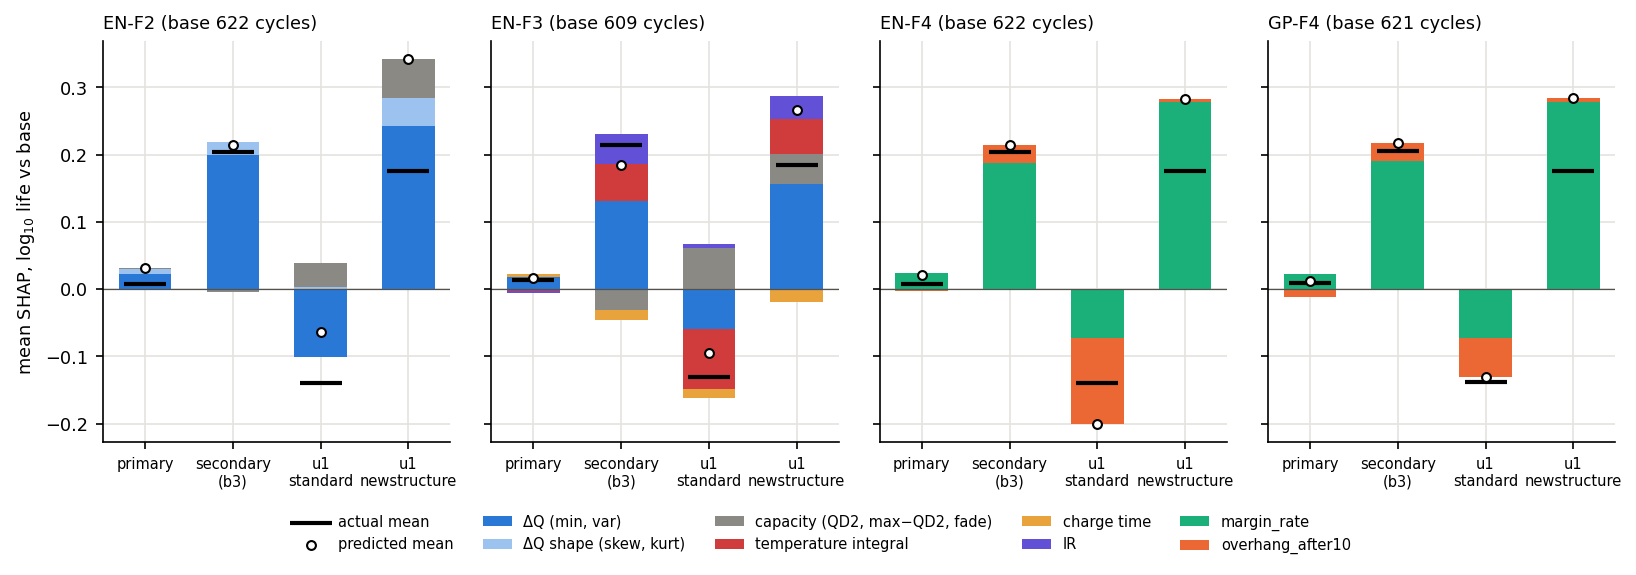

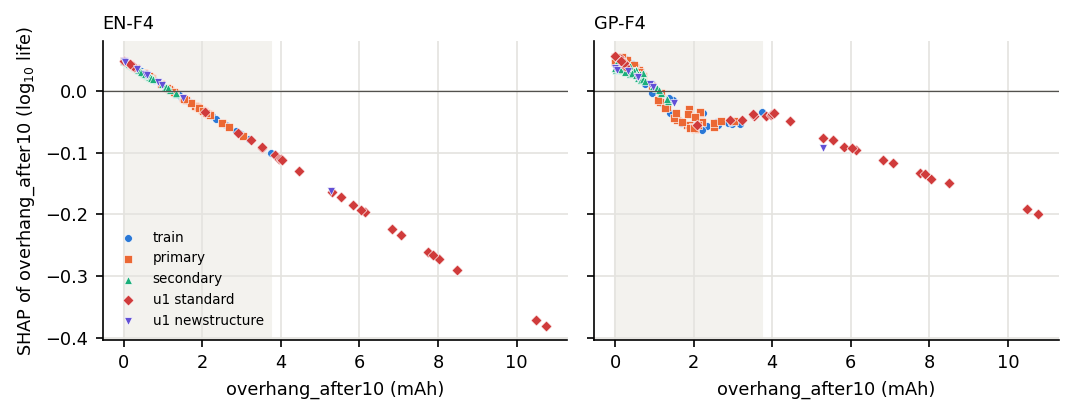

In [6]:
for m in ("EN-F2", "EN-F3", "GP-F4", "EN-F3+F4"):
    r = S[m]["sets"]
    t = pd.DataFrame({k: v["mean_abs"] for k, v in r.items()})
    t = t[t.sum(1) > 1e-6]
    print(f"\n{m}: share of mean |SHAP| (%)")
    display((100 * t / t.sum()).round(0))
display(Image(str(FIG / "fig_p5_shap.png"), width=980))
display(Image(str(FIG / "fig_p5_overhang.png"), width=700))

* **F2 over-predicts the standard cells because of their high initial capacity** (read as "healthy"), not the overhang.
* **F3 is right on them partly for the wrong reason:** the temperature integral (long cycles) cancels the capacity effect.
* **GP-F4 beats EN-F4 because the GP learned that the overhang effect saturates;** the linear model extrapolates it.
* **The `-newstructure` over-prediction comes from ΔQ itself:** these cells change their discharge curve less than
  cells of the same life elsewhere. The cause is open.

## 6 · Exploratory: GP on F3 + F4 (not pre-registered)

In [7]:
pd.DataFrame({k: {"nested CV log10": round(v["nested_cv_log"], 4), "train RMSE": round(v["train"]["rmse"]),
                  **{s: round(v[s]["rmse"]) for s in ("primary", "secondary", "u1_all", "u1_standard", "u1_newstructure")}}
              for k, v in G.items()}).T

,nested CV log10,train RMSE,primary,secondary,u1_all,u1_standard,u1_newstructure
GP-F3+F4,0.0626,19.0,112.0,210.0,129.0,35.0,261.0
EN-F3+F4,0.0525,65.0,122.0,205.0,124.0,28.0,254.0
GP-F4,0.0478,49.0,103.0,180.0,158.0,49.0,316.0
EN-F3,0.0526,67.0,125.0,220.0,138.0,51.0,271.0


The GP on eleven features nearly memorises the training cells and is no better than the elastic net on the same
features: **the GP works best with few, robust features.**

## 7 · Answer to RQ5
Transfer depends on how a new batch's procedure relates to the training batches: the standard u1 cells (like a training
batch) are predicted to within 5–10% by several models; the `-newstructure` cells are over-predicted by 17–50% by every
model. Which model transfers best differs between the two new batches. The GP on F4 is the most balanced choice.